# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno99", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

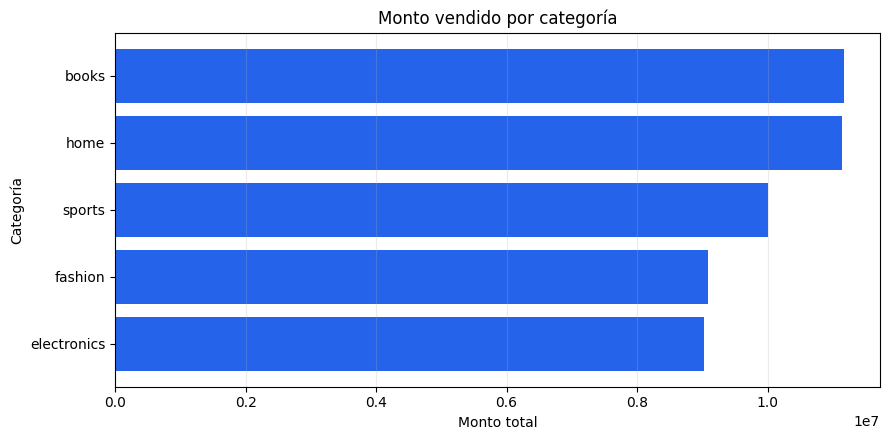

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

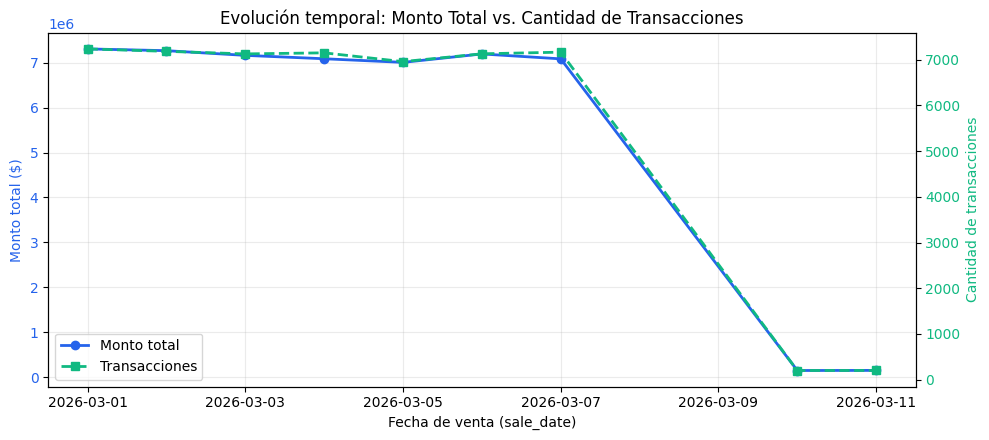

Respuesta: El 2026-03-01 tuvo el mayor monto vendido (7,310,840.77) y la mayor cantidad de transacciones (7236).


In [0]:
# Tu solución. Agregá por sale_date antes de convertir el resultado a Pandas.
# Incluí título, ejes, unidades y una respuesta escrita.
import pandas as pd

df_metrics = (
    spark.table(daily)
    .groupBy("sale_date")
    .agg(
        F.sum("total_amount").alias("total_amount"),
        F.sum("transaction_count").alias("total_transaction_count")
    )
    .orderBy("sale_date")
)

plot_data = df_metrics.toPandas()
plot_data['sale_date'] = pd.to_datetime(plot_data['sale_date'])

fig, ax1 = plt.subplots(figsize=(10, 4.5))

color_amount = "#2563eb"
ax1.set_xlabel("Fecha de venta (sale_date)")
ax1.set_ylabel("Monto total ($)", color=color_amount)
line1 = ax1.plot(plot_data['sale_date'], plot_data['total_amount'], color=color_amount, marker="o", linewidth=2, label="Monto total")
ax1.tick_params(axis='y', labelcolor=color_amount)
ax1.grid(True, alpha=0.25)

ax2 = ax1.twinx()  
color_trans = "#10b981"
ax2.set_ylabel("Cantidad de transacciones", color=color_trans)
line2 = ax2.plot(plot_data['sale_date'], plot_data['total_transaction_count'], color=color_trans, marker="s", linewidth=2, linestyle="--", label="Transacciones")
ax2.tick_params(axis='y', labelcolor=color_trans)

plt.title("Evolución temporal: Monto Total vs. Cantidad de Transacciones")

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="lower left")

fig.tight_layout()
plt.show()

leader_amount = plot_data.loc[plot_data['total_amount'].idxmax()]
leader_trans = plot_data.loc[plot_data['total_transaction_count'].idxmax()]

print(f"Respuesta: El {leader_amount['sale_date'].strftime('%Y-%m-%d')} tuvo el mayor monto vendido ({leader_amount['total_amount']:,.2f}) y la mayor cantidad de transacciones ({int(leader_trans['total_transaction_count'])}).")

Los máximos coinciden, esto significa que el promedio del valor de las transacciones suele ser similar.

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

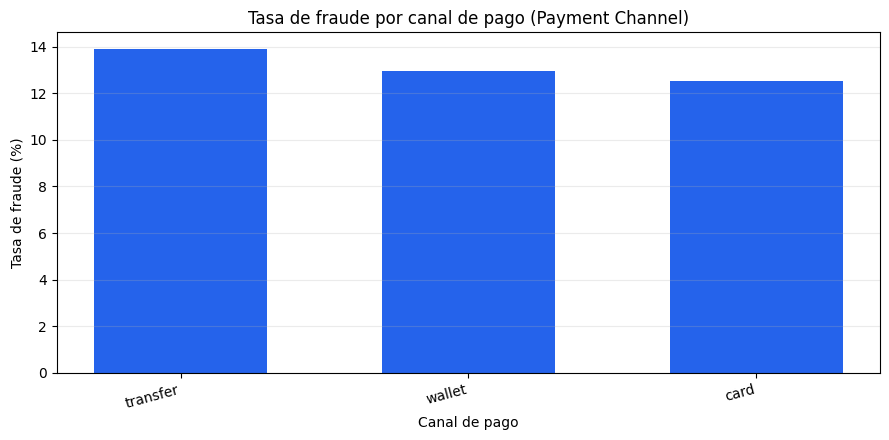

Respuesta: transfer es el canal con mayor tasa de fraude (13.91%), con 2,327 fraudes sobre 16,723 transacciones totales.

Promedio de transacciones por canal: 16,783.0

La conclusión sí se sostiene de forma sólida. El canal transfer no solo tiene la mayor tasa, sino que su volumen de transacciones (16,723) está en línea con el promedio general (16,783.0).

Detalle por canal:
- Canal: transfer | Tasa: 13.91% | Transacciones: 16,723 | Fraudes: 2,327
- Canal: wallet | Tasa: 12.97% | Transacciones: 16,724 | Fraudes: 2,169
- Canal: card | Tasa: 12.54% | Transacciones: 16,902 | Fraudes: 2,119


In [0]:
# Tu solución. Recalculá la tasa global como suma(fraud_transactions) / suma(transaction_count).
# Evitá promediar directamente fraud_rate entre grupos.
pay_channel_fraud_sales = (
    spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("fraud_transactions").alias("fraud_transactions"),
        F.sum("transaction_count").alias("transaction_count")
    )
    .withColumn(
        "fraud_rate", 
        F.when(F.col("transaction_count") > 0, F.col("fraud_transactions") / F.col("transaction_count"))
        .otherwise(0.0)
    )
    .orderBy(F.desc("fraud_rate"))
)

plot_data = pay_channel_fraud_sales.toPandas()
plot_data['fraud_rate_pct'] = plot_data['fraud_rate'] * 100

fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(plot_data["payment_channel"], plot_data['fraud_rate_pct'], color="#2563eb", width=0.6)

ax.set_title("Tasa de fraude por canal de pago (Payment Channel)")
ax.set_ylabel("Tasa de fraude (%)")
ax.set_xlabel("Canal de pago")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

full_data = pay_channel_fraud_sales.collect()
leader = full_data[0]

avg_transactions = sum(row.transaction_count for row in full_data) / len(full_data)

print(f"Respuesta: {leader.payment_channel} es el canal con mayor tasa de fraude ({leader.fraud_rate:.2%}), "
      f"con {leader.fraud_transactions:,} fraudes sobre {leader.transaction_count:,} transacciones totales.\n")

print(f"Promedio de transacciones por canal: {avg_transactions:,.1f}\n")

print(f"La conclusión sí se sostiene de forma sólida. El canal {leader.payment_channel} no solo tiene la mayor tasa, sino que su volumen de transacciones ({leader.transaction_count:,}) está en línea con el promedio general ({avg_transactions:,.1f}).")

print("\nDetalle por canal:")
for row in full_data:
    print(f"- Canal: {row.payment_channel} | Tasa: {row.fraud_rate:.2%} | Transacciones: {row.transaction_count:,} | Fraudes: {row.fraud_transactions:,}")

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

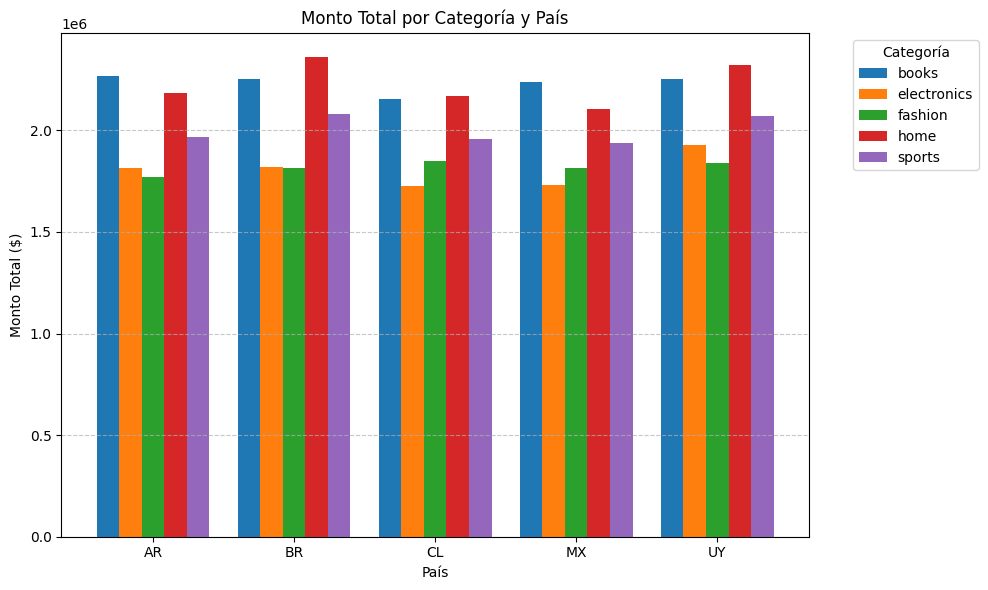

Respuesta: El mayor monto global se registró en BR con un total de $2,361,959.97 en la categoría 'home'.

Ordenados por monto:
- País: BR | Categoría: home | Monto Total: $2,361,959.97
- País: UY | Categoría: home | Monto Total: $2,323,924.46
- País: AR | Categoría: books | Monto Total: $2,267,722.26
- País: BR | Categoría: books | Monto Total: $2,252,988.52
- País: UY | Categoría: books | Monto Total: $2,252,955.97
- País: MX | Categoría: books | Monto Total: $2,235,941.63
- País: AR | Categoría: home | Monto Total: $2,184,148.34
- País: CL | Categoría: home | Monto Total: $2,167,748.03
- País: CL | Categoría: books | Monto Total: $2,155,673.48
- País: MX | Categoría: home | Monto Total: $2,105,216.34
- País: BR | Categoría: sports | Monto Total: $2,079,532.92
- País: UY | Categoría: sports | Monto Total: $2,069,971.18
- País: AR | Categoría: sports | Monto Total: $1,966,346.81
- País: CL | Categoría: sports | Monto Total: $1,955,752.03
- País: MX | Categoría: sports | Monto Total: $1

In [0]:
df_category_country = (
    spark.table(daily)
    .groupBy("category", "country")
    .agg(
        F.sum("total_amount").cast("double").alias("total_amount")
    )
    .orderBy(F.desc("total_amount"))
)

plot_data = df_category_country.toPandas()

df_pivot = plot_data.pivot(index='country', columns='category', values='total_amount').fillna(0)

fig, ax = plt.subplots(figsize=(10, 6))
df_pivot.plot(kind="bar", ax=ax, width=0.8)

plt.title("Monto Total por Categoría y País")
plt.xlabel("País")
plt.ylabel("Monto Total ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Categoría", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

leader = df_category_country.first()
print(f"Respuesta: El mayor monto global se registró en {leader.country} con un total de ${leader.total_amount:,.2f} en la categoría '{leader.category}'.\n")

print("Ordenados por monto:")
for row in df_category_country.collect():
    print(f"- País: {row.country} | Categoría: {row.category} | Monto Total: ${row.total_amount:,.2f}")

La categoría cambia según el mercado.
Este gráfico es adecuado ya que por colores permite rápidamente comparar las categoría para cada uno de los paises (en los distintos grupos de columnas). Y si se quiere hacer un análisis por país se pueden comparar las barras dentro de cada grupo.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

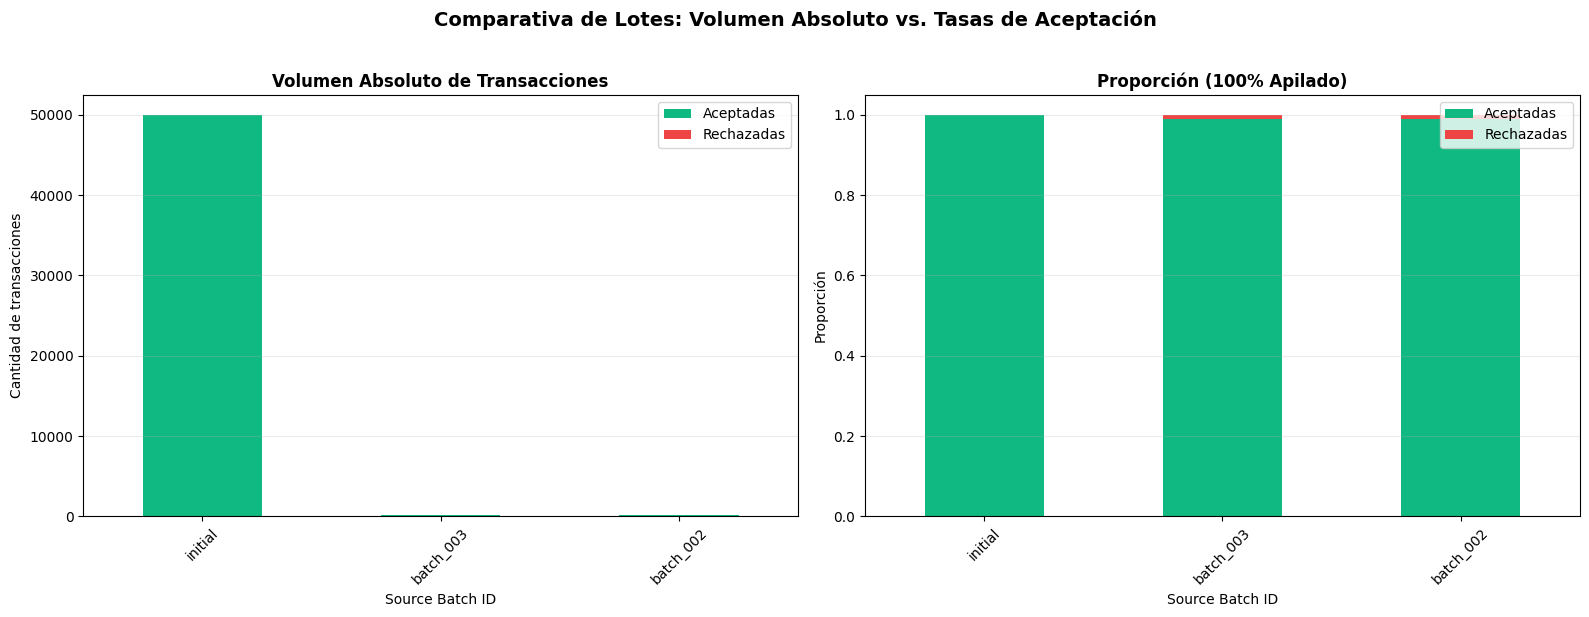

In [0]:
# Tu solución. Calculá total = accepted_transactions + rejected_transactions.
# Un gráfico de barras apiladas al 100% puede facilitar la comparación de proporciones.
dimension_col = "source_batch_id"

acc_transactions_sales = (
    spark.table(batch)
    .withColumn("total_trans", F.col("accepted_transactions") + F.col("rejected_transactions"))
    .withColumn(
        "acc_rate", 
        F.when(F.col("total_trans") > 0, F.col("accepted_transactions") / F.col("total_trans")).otherwise(0.0)
    )
    .withColumn(
        "arej_rate", 
        F.when(F.col("total_trans") > 0, F.col("rejected_transactions") / F.col("total_trans")).otherwise(0.0)
    )
    .orderBy(F.desc("acc_rate"))
)

pdf_data = (
    acc_transactions_sales
    .select(
        dimension_col, 
        "accepted_transactions", 
        "rejected_transactions", 
        "acc_rate", 
        "arej_rate"
    )
    .limit(20)
    .toPandas()
    .set_index(dimension_col)
)

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

pdf_data[["accepted_transactions", "rejected_transactions"]].plot(
    kind="bar", 
    stacked=True, 
    ax=ax1, 
    color=["#10b981", "#ef4444"]
)
ax1.set_title("Volumen Absoluto de Transacciones", fontsize=12, fontweight="bold")
ax1.set_xlabel("Source Batch ID", fontsize=10)
ax1.set_ylabel("Cantidad de transacciones", fontsize=10)
ax1.legend(["Aceptadas", "Rechazadas"], loc="upper right")
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis="y", alpha=0.25)

pdf_data[["acc_rate", "arej_rate"]].plot(
    kind="bar", 
    stacked=True, 
    ax=ax2, 
    color=["#10b981", "#ef4444"]
)
ax2.set_title("Proporción (100% Apilado)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Source Batch ID", fontsize=10)
ax2.set_ylabel("Proporción", fontsize=10)
ax2.legend(["Aceptadas", "Rechazadas"], loc="upper right")
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis="y", alpha=0.25)

plt.suptitle("Comparativa de Lotes: Volumen Absoluto vs. Tasas de Aceptación", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Comparar lotes de distintos tamaños no permite ver de manera clara las diferencias si solo evaluamos las proporciones. Se puede apreciar que 1 rechazado tiene mucho más impacto en la proporción de batch_002 y batch_003 que sobre initial por la cantidad total de transacciones.

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.